# PVP reproduction: results and decisions

Practical Work in AI, JKU Linz. Phase 4 results and Phase 5 replay check.

**Question.** Can we reproduce the published PVP results (Xue et al., 2026, Table 2,
MMS-300M with PVP) with the public code and the official benchmark protocols?

**Short answer.** Yes, closely. EN-Famous: EER 7.34% (paper 7.24%).
ZH-Famous: EER 12.24% (paper 11.37%). Both runs use the unchanged upstream code.

**Path through this notebook**

1. What PVP does
2. Decisions I made, and why
3. The data
4. The two scientific runs
5. Main result: our numbers vs. the paper
6. Looking inside the scores
7. Where errors come from (additional analysis)
8. Failed trials and robustness of the result
9. Replay: are the results repeatable?
10. Conclusion, limitations, next steps

This notebook only **reads saved run results**. It loads no model and no audio.
Every number below is recomputed from the per-trial scores files.

## 1. What PVP does

PVP is a *personalized* deepfake detector. It protects one known speaker,
the *person of interest* (POI), and needs only genuine recordings of that person.
It never trains on deepfakes.

1. **Enrollment.** For each POI, take about 100-200 genuine recordings.
2. **Phoneme features.** A phoneme recognizer (CTC) finds where each speech sound is.
   The MMS-300M model gives acoustic vectors; they are averaged per phoneme occurrence.
3. **Profile.** Fit one Gaussian mixture model (GMM) per phoneme, plus one GMM on
   speaker embeddings (ECAPA). The 12 most reliable phonemes form the "top-k" set.
4. **Test.** A new recording is scored against the claimed speaker's profile.
   Phoneme score and speaker score are fused (alpha = 0.8).
   **Higher score = more like the genuine speaker.**

If a recording has too few known phonemes, upstream falls back to broader tiers:
Level 1 (top-k phonemes), Level 2 (all phonemes), Level 3 (broad sound classes),
or `Extract Fail` (no phoneme features: phoneme score 0.5, speaker score still used).

Metrics: **EER** (equal error rate, lower is better) and **ROC-AUC** (higher is better),
computed with the upstream EER function and scikit-learn.

## 2. Decisions I made, and why

| Decision | Reason |
| --- | --- |
| Use the **unchanged upstream code** (`original/PVP/`, commit `1eed3f4`); our code only wraps and records | A reproduction must test the published method, not my version of it. |
| Use **code settings**, not paper-text settings, where they differ | The paper text and code differ (speaker sigmoid, GMM regularization, enrollment amount, ...). The code is what the authors published and can be run exactly. All differences are listed in `docs/reproduction.md`. |
| Use the **official protocols unchanged** | The paper's numbers come from these lists. Changing them would make the comparison meaningless. |
| **Record every trial**, including failed ones, with reason | Upstream prints errors and silently skips trials. For reproducibility, nothing may disappear without a record. |
| Report the **data problems** found before the runs, but do not remove trials | Removing trials after seeing results would be tuning on the test set. Their effect is shown separately (Section 8). |
| **Default backbone only** (MMS-300M) | Scope decision on 2026-11-11: it is the upstream default; other backbones are not reproduced. |
| Scientific runs only from a **clean, committed checkout**, with full provenance and W&B | So that every number can be traced to exact code, data, models and environment. |

In [1]:
import csv
import json
import sys
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import roc_curve

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "scripts"))
from evaluate_pvp import evaluate, metrics, read_scores  # same code as the runs

RUNS = {
    "ZH-Famous": {"run_id": "20261110T161146Z-a7e7dcab", "checks": "zh-famous",
                  "config": "configs/pvp-zh-famous-mms.json"},
    "EN-Famous": {"run_id": "20261110T194052Z-89c7e58d", "checks": "famous-figures",
                  "config": "configs/pvp-famous-figures-mms.json"},
}
BONAFIDE, SPOOF = "#2a78d6", "#eb6834"  # colorblind-safe pair
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:.2f}".format

for name, run in RUNS.items():
    folder = ROOT / "results/runs" / run["run_id"]
    run["rows"] = read_scores(folder / "scores.csv")
    run["record"] = json.loads((folder / "run.json").read_text())
    run["enrollment"] = json.loads((folder / "enrollment.json").read_text())
    run["paper"] = json.loads((ROOT / run["config"]).read_text())["paper"]
    print(f"{name}: {len(run['rows']):,} trials loaded from {run['run_id']}")

ZH-Famous: 203,921 trials loaded from 20261110T161146Z-a7e7dcab


EN-Famous: 347,021 trials loaded from 20261110T194052Z-89c7e58d


## 3. The data

Two benchmarks from the authors: **ZH-Famous** (Mandarin, 10 speakers) and
**EN-Famous** ("Famous Figures", English, 10 speakers). Each speaker has a fixed
enrollment list and a test list with genuine (bona fide) and deepfake (spoof) trials.

Note the strong imbalance: a few speakers dominate the test set,
and spoofs outnumber bona fide trials about 5 to 1.

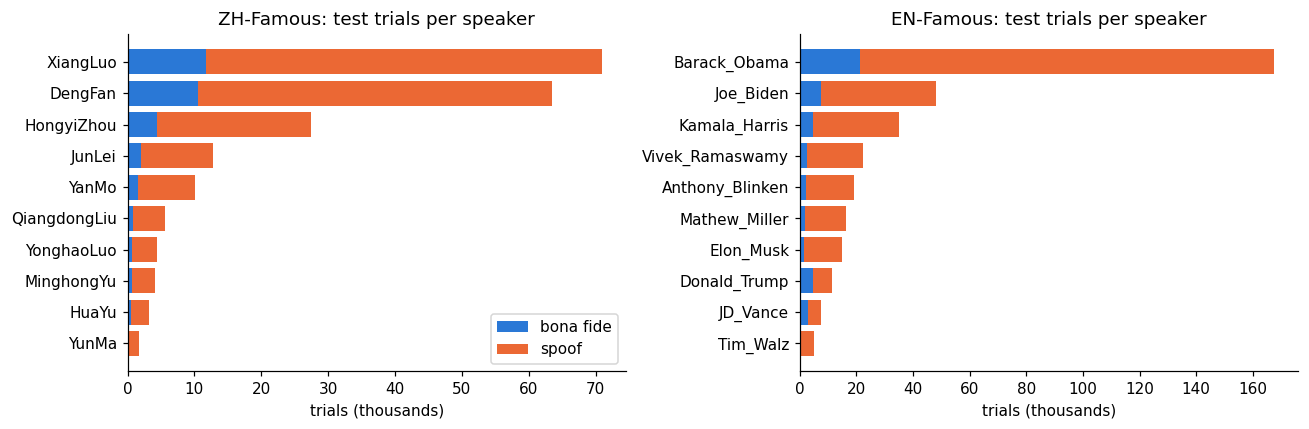

ZH-Famous: 1,023 enrollment files, 32,991 bona fide and 170,930 spoof test trials, 5 spoof systems: F5, LLaSA, OpenAudio-S1-mini, VOXCPM, indextts
EN-Famous: 1,115 enrollment files, 49,151 bona fide and 297,870 spoof test trials, 11 spoof systems: COZYVOICE2, E2TTS, F5TTS, FISHSPEECH, LLASA, MASKGCT, PARLER, SSRSPEECH, STYLETTS2, XTTSV2, ZONOS


In [2]:
def trial_table(run):
    counts = Counter((r["speaker"], r["label"]) for r in run["rows"])
    speakers = sorted({s for s, _ in counts})
    return pd.DataFrame({
        "enroll files": [run["enrollment"][s]["files"] for s in speakers],
        "bona fide": [counts[(s, "bonafide")] for s in speakers],
        "spoof": [counts[(s, "spoof")] for s in speakers],
    }, index=speakers)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (name, run) in zip(axes, RUNS.items()):
    table = trial_table(run).sort_values("spoof")
    ax.barh(table.index, table["bona fide"], color=BONAFIDE, label="bona fide")
    ax.barh(table.index, table["spoof"], left=table["bona fide"], color=SPOOF, label="spoof")
    ax.set_title(f"{name}: test trials per speaker")
    ax.set_xlabel("trials (thousands)")
    ax.xaxis.set_major_formatter(lambda v, _: f"{v / 1000:.0f}")
axes[0].legend(loc="lower right")
plt.tight_layout()
plt.show()

for name, run in RUNS.items():
    table = trial_table(run)
    systems = sorted({r["source"] for r in run["rows"] if r["label"] == "spoof"})
    print(f"{name}: {table['enroll files'].sum():,} enrollment files, "
          f"{table['bona fide'].sum():,} bona fide and {table['spoof'].sum():,} spoof test trials, "
          f"{len(systems)} spoof systems: {', '.join(systems)}")

### Data problems found before the runs (Phase 3)

I decoded every file and compared audio hashes before running PVP. Two findings matter:

- **Exact copies.** Some bona fide *test* files are byte-identical to *enrollment* files
  of the same speaker. The detector has seen exactly this audio during enrollment.
- **Very short spoofs.** Some deepfake files are only 10-40 ms long. These later fail
  in the speaker model (Section 8).

The protocols stay unchanged (decision above); the effect is measured in Section 8.

In [3]:
for name, run in RUNS.items():
    report = json.loads((ROOT / f"results/datasets/{run['checks']}-leakage.json").read_text())
    copies = report["identical_audio"]["test_trials_equal_to_enroll_same_speaker"]["bonafide"]
    bonafide = sum(r["label"] == "bonafide" for r in run["rows"])
    print(f"{name}: {copies} bona fide test trials are copies of enrollment files "
          f"({100 * copies / bonafide:.2f}% of bona fide trials); "
          f"{report['rows_without_audio']} protocol files missing from the release")

ZH-Famous: 60 bona fide test trials are copies of enrollment files (0.18% of bona fide trials); 9 protocol files missing from the release
EN-Famous: 34 bona fide test trials are copies of enrollment files (0.07% of bona fide trials); 0 protocol files missing from the release


## 4. The two scientific runs

Both runs were started with `--scientific`, which refuses a dirty checkout.
The run record stores the code, models, data and environment behind each number.

In [4]:
def provenance(run):
    rec = run["record"]
    return {
        "run id": rec["run_id"],
        "scientific result": rec["scientific_result"],
        "our commit": rec["git"]["commit"][:7] + (" (dirty)" if rec["git"]["dirty"] else " (clean)"),
        "upstream commit": rec["upstream_commit"][:7],
        "config sha256": rec["config_sha256"][:12],
        "MMS weights sha256": rec["weights_sha256"]["mms-300m-anti-deepfake/mms_300m.ckpt"][:12],
        "GPU": rec["environment"]["gpu"].split(",")[0],
        "torch / CUDA": f"{rec['environment']['packages']['torch']} / {rec['environment']['torch_cuda']}",
        "started / finished": f"{rec['started_at'][:16]} / {rec['finished_at'][:16]}",
        "command": " ".join(rec["command"][1:]),
    }

pd.DataFrame({name: provenance(run) for name, run in RUNS.items()})

,ZH-Famous,EN-Famous
run id,20261110T161146Z-a7e7dcab,20261110T194052Z-89c7e58d
scientific result,True,True
our commit,f806ba8 (clean),5c761cf (clean)
upstream commit,1eed3f4,1eed3f4
config sha256,06202412dcb9,cb07c2d7ad99
MMS weights sha256,c4dc55e229d9,c4dc55e229d9
GPU,NVIDIA GeForce RTX 4070 Ti SUPER,NVIDIA GeForce RTX 4070 Ti SUPER
torch / CUDA,2.6.0 / 12.4,2.6.0 / 12.4
started / finished,2026-11-10T16:11 / 2026-11-10T19:23,2026-11-10T19:40 / 2026-11-11T01:17
command,scripts/run_pvp.py configs/pvp-zh-famous-mms.j...,scripts/run_pvp.py configs/pvp-famous-figures-...


## 5. Main result: our numbers vs. the paper

Metrics are recomputed here from `scores.csv` with the same evaluator the runner used,
and checked against the saved `metrics.json`.

In [5]:
rows = []
for name, run in RUNS.items():
    run["result"] = evaluate(run["rows"])
    saved = json.loads((ROOT / "results/runs" / run["run_id"] / "metrics.json").read_text())
    assert run["result"]["pooled"] == saved["pooled"], "recomputed metrics differ from saved run"
    ours = run["result"]["pooled"]
    paper = run["paper"]
    rows.append({"benchmark": name,
                 "paper EER": paper["eer_percent"], "our EER": 100 * ours["eer"],
                 "paper AUC": paper["auc_percent"], "our AUC": 100 * ours["auc"]})

table = pd.DataFrame(rows).set_index("benchmark")
table["EER diff"] = table["our EER"] - table["paper EER"]
table["AUC diff"] = table["our AUC"] - table["paper AUC"]
print("Recomputed metrics equal the saved run metrics. Values in percent.")
table[["paper EER", "our EER", "EER diff", "paper AUC", "our AUC", "AUC diff"]]

Recomputed metrics equal the saved run metrics. Values in percent.


,paper EER,our EER,EER diff,paper AUC,our AUC,AUC diff
benchmark,,,,,,
ZH-Famous,11.37,12.24,0.87,94.58,93.62,-0.96
EN-Famous,7.24,7.34,0.10,96.61,96.58,-0.03


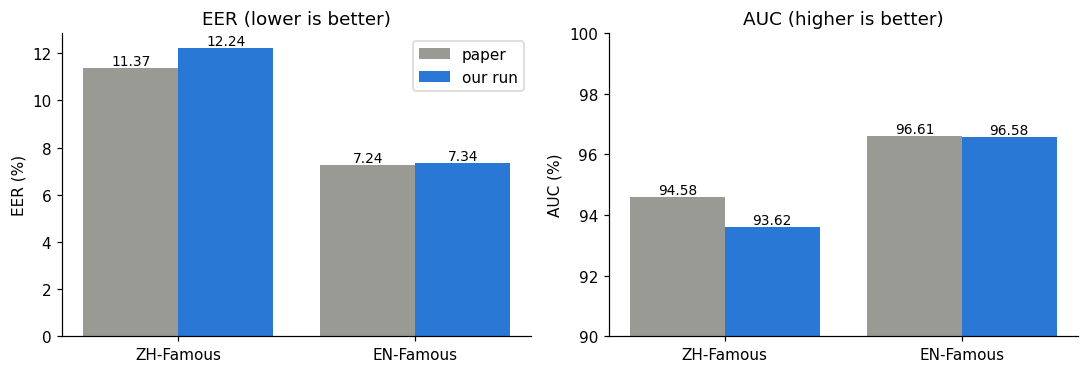

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
x = np.arange(len(table))
for ax, metric in zip(axes, ["EER", "AUC"]):
    ax.bar(x - 0.2, table[f"paper {metric}"], 0.4, color="#9a9a94", label="paper")
    ax.bar(x + 0.2, table[f"our {metric}"], 0.4, color=BONAFIDE, label="our run")
    for i, (p, o) in enumerate(zip(table[f"paper {metric}"], table[f"our {metric}"])):
        ax.text(i - 0.2, p, f"{p:.2f}", ha="center", va="bottom", fontsize=9)
        ax.text(i + 0.2, o, f"{o:.2f}", ha="center", va="bottom", fontsize=9)
    ax.set_xticks(x, table.index)
    ax.set_ylabel(f"{metric} (%)")
    ax.set_title(f"{metric} ({'lower' if metric == 'EER' else 'higher'} is better)")
    if metric == "AUC":
        ax.set_ylim(90, 100)
axes[0].legend()
plt.tight_layout()
plt.show()

**Reading.** EN-Famous matches the paper within 0.1 points. ZH-Famous is about
one point worse. The cause of that gap is not established; candidates are the
paper/code settings differences, the 9 missing release files, and an unknown code
state behind the published table. Nothing was tuned toward the paper values.

The paper's "Pooled" column is the mean of the two datasets (checked for all 20 values
in Table 2). With that rule: our EER 9.79 vs. paper 9.305, AUC 95.10 vs. 95.59.

## 6. Looking inside the scores

PVP scores are **strongly saturated**: most scores are between 0.9999 and 1.
On a normal axis everything sits in one bar. So the plot shows
$-\log_{10}(1 - \text{score})$: a value of 5 means score = 0.99999.
This transform keeps the order of scores, so EER and AUC are unchanged.

The dashed line is the EER threshold: trials to the right are accepted as genuine.

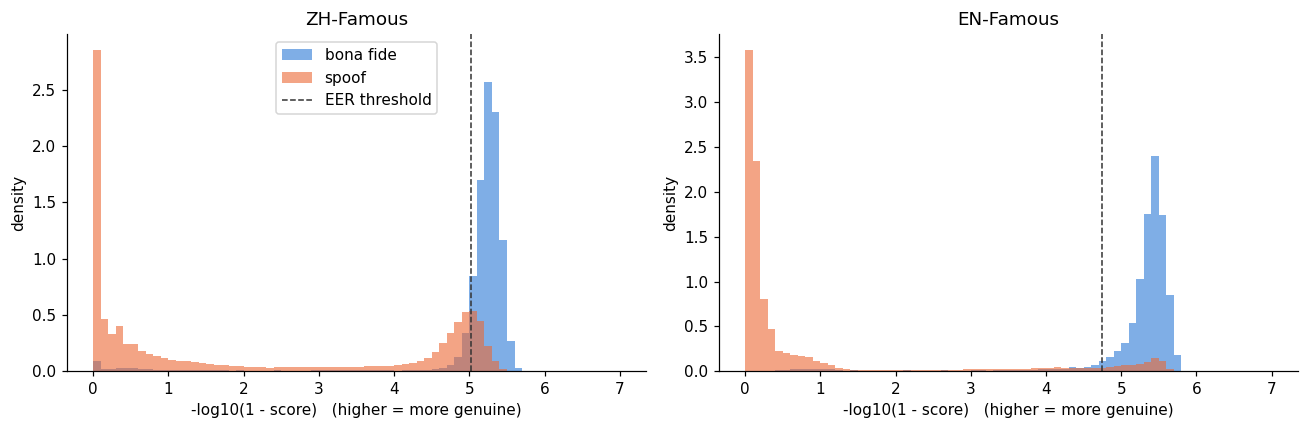

In [7]:
def nines(scores):
    return -np.log10(np.clip(1 - np.asarray(scores), 1e-16, None))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (name, run) in zip(axes, RUNS.items()):
    scored = [r for r in run["rows"] if r["status"] == "scored"]
    bins = np.linspace(0, 7, 71)  # last bin also holds the few values above 7
    for label, color in [("bonafide", BONAFIDE), ("spoof", SPOOF)]:
        values = np.clip(nines([float(r["score"]) for r in scored if r["label"] == label]), 0, 7)
        ax.hist(values, bins=bins, density=True, alpha=0.6, color=color,
                label="bona fide" if label == "bonafide" else "spoof")
    ax.axvline(nines(run["result"]["pooled"]["eer_threshold"]), color="#333", ls="--", lw=1,
               label="EER threshold")
    ax.set_title(name)
    ax.set_xlabel("-log10(1 - score)   (higher = more genuine)")
    ax.set_ylabel("density")
axes[0].legend()
plt.tight_layout()
plt.show()

**Reading.** Bona fide and spoof scores are clearly separated, but with a long overlap
region. The saturation comes from the upstream sigmoid settings. All score files keep
full precision, so the saturation does not create artificial ties.

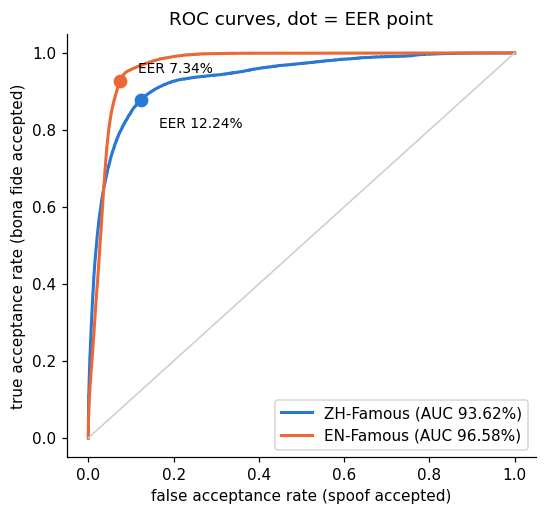

In [8]:
fig, ax = plt.subplots(figsize=(5.5, 5))
for (name, run), color, offset in zip(RUNS.items(), [BONAFIDE, SPOOF], [(12, -18), (12, 6)]):
    scored = [r for r in run["rows"] if r["status"] == "scored"]
    labels = [r["label"] == "bonafide" for r in scored]
    fpr, tpr, _ = roc_curve(labels, [float(r["score"]) for r in scored])
    eer = run["result"]["pooled"]["eer"]
    ax.plot(fpr, tpr, color=color, lw=2,
            label=f"{name} (AUC {100 * run['result']['pooled']['auc']:.2f}%)")
    ax.plot(eer, 1 - eer, "o", color=color, ms=8)
    ax.annotate(f"EER {100 * eer:.2f}%", (eer, 1 - eer), xytext=offset,
                textcoords="offset points", fontsize=9)
ax.plot([0, 1], [0, 1], color="#ccc", lw=1)
ax.set_xlabel("false acceptance rate (spoof accepted)")
ax.set_ylabel("true acceptance rate (bona fide accepted)")
ax.set_title("ROC curves, dot = EER point")
ax.legend(loc="lower right")
plt.show()

## 7. Where errors come from

> **Additional analysis, not part of the paper comparison.** It uses the same scores;
> the main result in Section 5 does not change.

Two questions: which speakers are hard, and which deepfake systems are hard?
For one system, all bona fide trials are compared with only that system's spoofs.

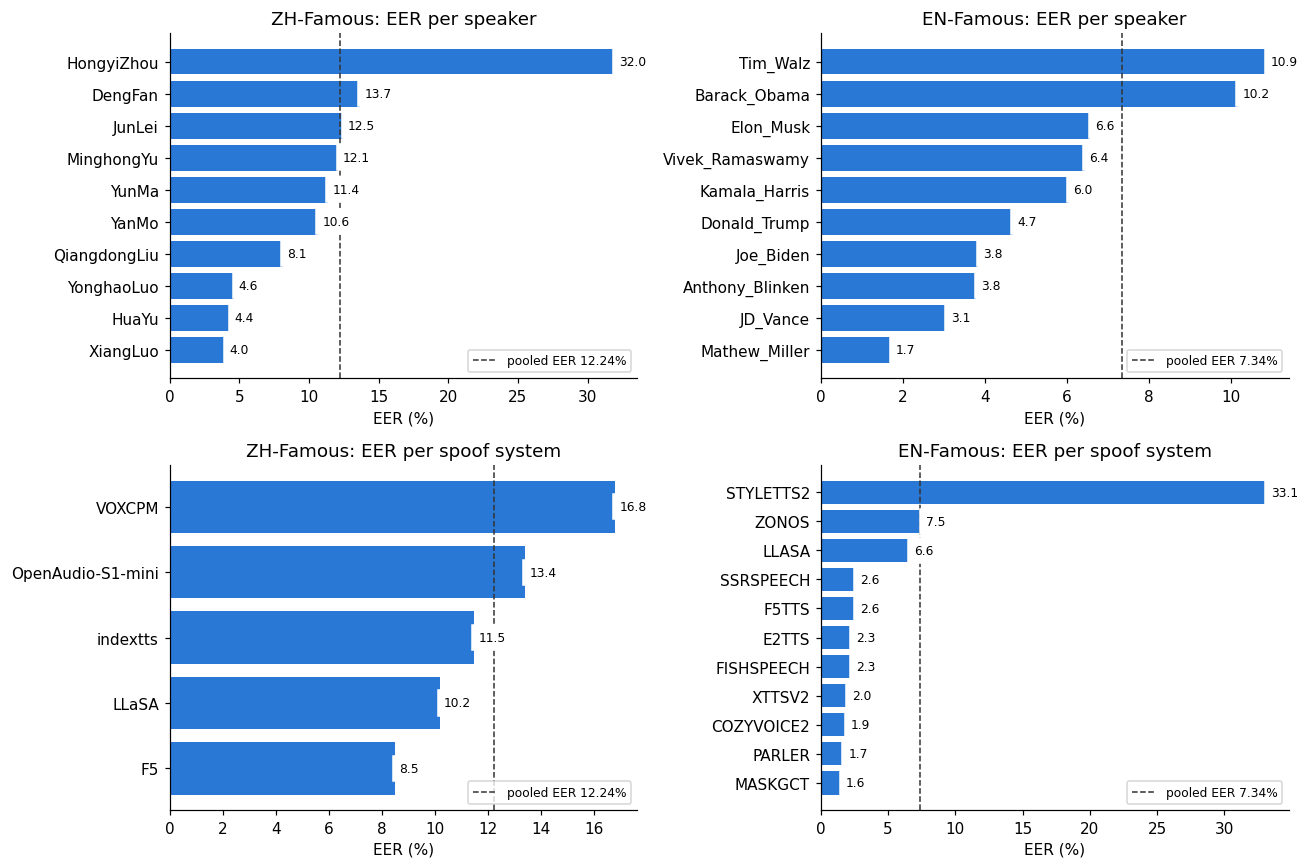

In [9]:
def per_system(run):
    scored = [r for r in run["rows"] if r["status"] == "scored"]
    bona = [float(r["score"]) for r in scored if r["label"] == "bonafide"]
    result = {}
    for system in sorted({r["source"] for r in scored if r["label"] == "spoof"}):
        spoof = [float(r["score"]) for r in scored if r["source"] == system and r["label"] == "spoof"]
        result[system] = 100 * metrics([1] * len(bona) + [0] * len(spoof), bona + spoof)["eer"]
    return pd.Series(result).sort_values()

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for col, (name, run) in enumerate(RUNS.items()):
    pooled = 100 * run["result"]["pooled"]["eer"]
    speakers = pd.Series({s: 100 * m["eer"] for s, m in run["result"]["per_speaker"].items()}).sort_values()
    systems = per_system(run)
    for ax, series, what in [(axes[0, col], speakers, "speaker"), (axes[1, col], systems, "spoof system")]:
        ax.barh(series.index, series.values, color=BONAFIDE)
        ax.axvline(pooled, color="#333", ls="--", lw=1, label=f"pooled EER {pooled:.2f}%")
        for i, v in enumerate(series.values):
            ax.text(v + 0.01 * series.max(), i, f"{v:.1f}", va="center", fontsize=8,
                    backgroundcolor="white")
        ax.set_title(f"{name}: EER per {what}")
        ax.set_xlabel("EER (%)")
        ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

**Reading.**

- **ZH-Famous:** HongyiZhou is a clear outlier (EER about 32%). The reason is not
  investigated yet. VOXCPM is the hardest system.
- **EN-Famous:** most systems are easy (EER below 3%). **STYLETTS2** is the exception
  (EER about 33%): PVP does not detect it well. Barack_Obama has 48% of all test trials,
  so he strongly shapes the pooled result.
- The pooled EER hides large differences. For a personalized detector,
  the per-speaker view is the more honest one.

## 8. Failed trials and robustness of the result

Upstream skips trials that raise an error, and gives a neutral phoneme score (0.5)
when no phoneme features can be extracted. Our runner records both.

In [10]:
summary = {}
for name, run in RUNS.items():
    failed = [r for r in run["rows"] if r["status"] != "scored"]
    tiers = run["result"]["tiers"]
    summary[name] = {
        "trials": len(run["rows"]),
        "failed": len(failed),
        "failed, missing file": sum(r["error"].startswith("missing_file") for r in failed),
        "failed, spoof": sum(r["label"] == "spoof" for r in failed),
        **{f"tier: {t}": n for t, n in sorted(tiers.items())},
    }
pd.DataFrame(summary).fillna(0).astype(int)

,ZH-Famous,EN-Famous
trials,203921,347021
failed,10,333
"failed, missing file",9,0
"failed, spoof",10,333
tier: Extract Fail + ASV,1060,3225
tier: Level 1 (Top-K GMM) + ASV,140007,340263
tier: Level 2 (All GMM) + ASV,62559,2685
tier: Level 3 (Broad GMM) + ASV,285,515


All failed trials are spoofs: 9 files are missing from the ZH release, and the others are
10-40 ms files where the speaker model (ECAPA) raises an error. Like upstream, they are
excluded from the metrics. Two checks show they do not change the conclusion:

1. **Worst case:** count every failed spoof as accepted (score = 1).
2. **Without copies:** remove the bona fide test trials that are copies of enrollment files.

In [11]:
def enrollment_copies(name):
    # Test bona fide files in the same identical-audio group as an enrollment file.
    groups = defaultdict(list)
    path = ROOT / f"results/datasets/{RUNS[name]['checks']}-identical-audio.csv"
    with path.open(newline="") as stream:
        for row in csv.DictReader(stream):
            groups[row["group"]].append(row)
    copies = set()
    for members in groups.values():
        enrolled = {m["speaker"] for m in members if m["split"] == "enroll"}
        copies |= {(m["speaker"], m["file"]) for m in members
                   if m["split"] == "test" and m["label"] == "bonafide" and m["speaker"] in enrolled}
    return copies


def eer_auc(rows):
    labels = [r["label"] == "bonafide" for r in rows]
    result = metrics(labels, [float(r["score"]) for r in rows])
    return round(100 * result["eer"], 2), round(100 * result["auc"], 2)


checks = {}
for name, run in RUNS.items():
    scored = [r for r in run["rows"] if r["status"] == "scored"]
    worst = scored + [{**r, "score": "1.0"} for r in run["rows"] if r["status"] != "scored"]
    copies = enrollment_copies(name)
    clean = [r for r in scored if (r["speaker"], r["file"]) not in copies]
    checks[name] = {
        "main result (EER, AUC)": eer_auc(scored),
        "failed spoofs accepted": eer_auc(worst),
        "without enrollment copies": eer_auc(clean),
        "copies removed": len(scored) - len(clean),
    }
pd.DataFrame(checks)

,ZH-Famous,EN-Famous
"main result (EER, AUC)","(12.24, 93.62)","(7.34, 96.58)"
failed spoofs accepted,"(12.24, 93.61)","(7.42, 96.47)"
without enrollment copies,"(12.26, 93.61)","(7.34, 96.58)"
copies removed,60,34


**Reading.** Both effects are below 0.1 EER points. The data problems are real,
but they do not explain the gap to the paper or change the conclusion.

## 9. Replay: are the results repeatable?

A result is only useful if the same command gives the same answer again. In Phase 5,
each scientific run was **started a second time** from a clean, committed checkout,
under a new run ID, with the same config, protocols, models and environment.
`scripts/compare_runs.py` then compares the original and the replay trial by trial.

**Pass rule (fixed before the replays ran, 2026-11-11):** the trial set, labels,
statuses, tiers and failure reasons must be identical. Score differences do not fail
a replay, but they are always reported: upstream leaves GPU (cuDNN) kernels
non-deterministic, so tiny floating-point differences are possible.

The small smoke checks from Phase 4 are compared the same way.

In [ ]:
from compare_runs import compare  # same code as the command-line replay check

REPLAYS = {  # (original run, replay run)
    ("ZH-Famous", "smoke check"): ("20261110T160411Z-47465f87", "20261110T160708Z-f4cdd955"),
    ("EN-Famous", "smoke check"): ("20261110T193420Z-ec42b331", "20261110T193658Z-38b6699d"),
    ("ZH-Famous", "full run"): (RUNS["ZH-Famous"]["run_id"], "20261111T055700Z-81928368"),
    ("EN-Famous", "full run"): (RUNS["EN-Famous"]["run_id"], "20261111T055547Z-4112a99e"),
}

reports, replay_rows = {}, {}
for key, (original, replay) in REPLAYS.items():
    report = compare(ROOT / "results/runs" / original, ROOT / "results/runs" / replay)
    reports[key] = report
    score = report["scores"]["score"]
    replay_rows[key] = {
        "replay run": replay,
        "trials": report["trials"]["trials"][1],
        "trials, tiers, failures identical": report["trials"]["identical"],
        "scores identical": f"{score['identical']:,} of {report['scores']['compared']:,}",
        "largest score difference": f"{score['max_abs_difference']:.1e}",
        "EER difference (points)": f"{report['metrics']['eer']['difference_points']:+.4f}",
        "AUC difference (points)": f"{report['metrics']['auc']['difference_points']:+.4f}",
        "speaker profiles identical": report["provenance"]["profiles_identical"],
        "replay passes": report["replay_pass"],
    }
pd.DataFrame(replay_rows)

In [ ]:
# What differs in the run records, apart from the per-trial results?
for key, report in reports.items():
    record = report["provenance"]["record"]
    shown = {k: v for k, v in record.items() if k != "environment.installed"}
    print(f"{' / '.join(key)}: {len(record)} differing record fields")
    for field, (a, b) in shown.items():
        print(f"    {field}: {a} -> {b}")
    if "environment.installed" in record:
        before, after = record["environment.installed"]
        print(f"    environment.installed: not recorded -> {len(after)} packages listed")
    if report["provenance"]["config"]:
        print(f"    resolved config differs: {report['provenance']['config']}")

**Reading.** _Filled in after the full replays finish._

## 10. Conclusion, limitations, next steps

**Conclusion.** The published MMS-300M PVP results are reproduced closely with the
unchanged public code and the official protocols: very close on EN-Famous (+0.10 EER points),
about one point apart on ZH-Famous (+0.87).

**Limitations**

- Settings follow the public code, which differs from the paper text in several places;
  the exact configuration behind Table 2 is unknown.
- Only the default MMS-300M backbone; the original-backbone baselines of Table 2 are not run
  (the upstream baseline script imports a missing package).
- Replay: see Section 9.
- Both benchmarks contain enrollment/test copies and very short spoofs (effect < 0.1 points).
- GPU kernels are not set to deterministic mode.

**Next steps (to discuss)**

- Phase 5: full-run replays are done (Section 9).
- Phase 6: choose additional datasets; German/English and cross-language evaluation
  are possible directions.
- Open questions from these results: why HongyiZhou and STYLETTS2 are so hard.

Details and evidence: `docs/reproduction.md`. W&B runs: see `run.json` of each run.